zsh:1: command not found: snap


In [77]:
import torch
from torch import optim
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

import torchvision
import torch.nn as nn
from torchvision.transforms import v2

import torch.nn.functional as F


import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [ ]:
train = pd.read_csv('sign_mnist_train.csv')
test  = pd.read_csv('sign_mnist_test.csv')
'''
train_imgs = train.loc[:, "pixel1":"pixel784"].values.reshape(27455,28,28,1) / 255.0
test_imgs = test.loc[:, "pixel1":"pixel784"].values.reshape(7172,28,28,1) / 255.0
test_labels = test.loc[:, "label"].values
'''

In [32]:
train.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


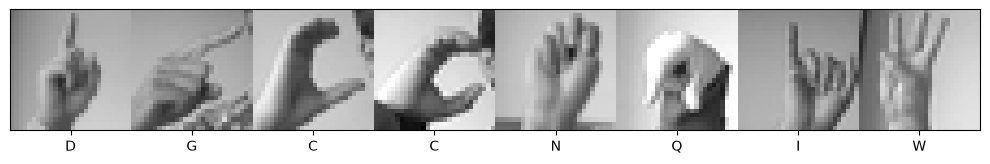

In [ ]:

pixel_columns = [column for column in train.columns if column != "label"]
images = train.loc[:7, pixel_columns].to_numpy().reshape(8, 28, 28)
letters = [chr(ord("A") + int(label)) for label in train.loc[:7, "label"]]
image_strip = np.concatenate(list(images), axis=1)

plt.figure(figsize=(10, 2.6))
plt.imshow(image_strip, cmap="gray", vmin=0, vmax=255)
plt.xticks(28 * np.arange(8) + 13.5, letters)
plt.yticks([])
plt.tight_layout()
plt.show()

In [100]:
npimg = train.loc[0].to_numpy() / 255.0
print(npimg)



AttributeError: 'function' object has no attribute 'loc'

In [101]:
class ImageDataset(Dataset):
    def __init__(self, frame):
        print(type(frame))
        pixels = frame.drop(columns="label")
        pixels = pixels.to_numpy(dtype=np.float32)
        labels = frame["label"].to_numpy(dtype=np.float32)
        self.images = torch.from_numpy(pixels) / 255.0
        self.labels = torch.from_numpy(labels)
        self.transform = transforms.resize((28,28))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        self.images[index] = self.transform(self.images[index])
        return self.images[index], self.labels[index]




In [102]:
train_data = ImageDataset(train)
test_data = ImageDataset(test)

# print(train_data.__getitem__(0).shape())

train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

<class 'function'>


AttributeError: 'function' object has no attribute 'drop'

In [74]:
class SignLanguageCNN(nn.Module):

    def __init__(self, in_channels, num_classes):
        super(SignLanguageCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=8, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(16 * 7 * 7, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = x.reshape(x.shape[0], -1)
        x = self.fc1(x)
        return x
        x = x.reshape(x.shape[0], -1)
        return x


In [65]:
model = SignLanguageCNN(in_channels=1, num_classes=26).to(device)
print(model)

SignLanguageCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=784, out_features=26, bias=True)
)


In [29]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [99]:
num_epochs = 10

def train(dataloader_train):
    for epoch in range(num_epochs):
        print(f"Epoch [{epoch+1}/{num_epochs}]")

        # iterating over batches of data
        for i, data in enumerate(dataloader_train):
            inputs, labels = data
            inputs = inputs.float()
            scores = model(inputs)
            loss = criterion(scores, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()


In [103]:
train(train_dataloader)

Epoch [1/10]


RuntimeError: Expected 3D (unbatched) or 4D (batched) input to conv2d, but got input of size: [64, 784]

add more data! (rotating, flipping, etc.)
change up the convolutions (what functions/optimizers used)
apply transforms
optimize batch size, learning rate via hypergradient descent
make hostable on a website (vercel/supabase)
add signs for common words
